Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


Load Dataset

In [ ]:
# load dataset
df = pd.read_csv('drive/MyDrive/My room/skripsi/data_labeling_6.csv')
df.head()

,Datetime,Tweet Id,Text,Username,Permalink,User,Outlinks,CountLinks,ReplyCount,RetweetCount,...,QuotedTweet,MentionedUsers,hashtag,hastag_counts,Cleaned_Text,Tokens,Word_Count,Text_For_VADER,Compound_Score,Sentiment
0,2023-01-22 13:44:39+00:00,1617156291046133761,@AlexandrovnaIng Prohibition of ChatGPT has be...,Caput_LupinumSG,https://twitter.com/Caput_LupinumSG/status/161...,https://twitter.com/Caput_LupinumSG,NaN,NaN,1,0,...,NaN,"[User(username='AlexandrovnaIng', id=282705900...",[],0,Prohibition of ChatGPT has been added to the h...,"['Prohibition', 'of', 'ChatGPT', 'has', 'been'...",15,Prohibition of ChatGPT has been added to the h...,0.4939,Positive
1,2023-01-22 13:44:49+00:00,1617156332297256961,Bow down to chatGPT 🫡..... https://t.co/ENTSzi...,Vishwasrisiri,https://twitter.com/Vishwasrisiri/status/16171...,https://twitter.com/Vishwasrisiri,['https://twitter.com/agadmator/status/1617155...,['https://t.co/ENTSzi2AQ9'],0,0,...,https://twitter.com/agadmator/status/161715501...,NaN,[],0,Bow down to chatGPT,"['Bow', 'down', 'to', 'chatGPT']",4,Bow down to chatGPT,0.0000,Neutral
2,2023-01-22 13:45:03+00:00,1617156389217894400,ChatGPT runs 10K Nvidia training GPUs with pot...,FierceElectron,https://twitter.com/FierceElectron/status/1617...,https://twitter.com/FierceElectron,['https://www.fierceelectronics.com/sensors/ch...,['https://t.co/Uhq62t0Uw4'],0,0,...,NaN,NaN,[],0,ChatGPT runs 10K Nvidia training GPUs with pot...,"['ChatGPT', 'runs', '10K', 'Nvidia', 'training...",11,ChatGPT runs 10K Nvidia training GPUs with pot...,0.0000,Neutral
3,2023-01-22 13:45:04+00:00,1617156393898745858,@SWENGDAD There is repetitive work in every jo...,xlr8harder,https://twitter.com/xlr8harder/status/16171563...,https://twitter.com/xlr8harder,NaN,NaN,1,0,...,NaN,"[User(username='SWENGDAD', id=1460452950875193...",[],0,There is repetitive work in every job there ar...,"['There', 'is', 'repetitive', 'work', 'in', 'e...",29,There is repetitive work in every job there ar...,-0.2500,Negative
4,2023-01-22 13:45:06+00:00,1617156404137295878,I created a fictional jewelry brand using Chat...,Kosuke_dazo,https://twitter.com/Kosuke_dazo/status/1617156...,https://twitter.com/Kosuke_dazo,['https://oriori.my.canva.site/'],['https://t.co/gtWdNZ0laM'],0,1,...,NaN,NaN,"['#ChatGPT', '#midjourney']",2,I created a fictional jewelry brand using Chat...,"['I', 'created', 'a', 'fictional', 'jewelry', ...",12,I created a fictional jewelry brand using Chat...,0.2500,Positive


 Filter Positif & Negatif

In [ ]:
df = df[df['Sentiment'].isin(['Positive', 'Negative'])]
print("Distribusi Sentimen:")
print(df['Sentiment'].value_counts())

Distribusi Sentimen:
Sentiment
Positive    15497
Negative     5702
Name: count, dtype: int64


Feature Extraction (TF-IDF)

In [ ]:
# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    stop_words='english',
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

# Replace NaN with empty strings
df['Text_For_VADER'] = df['Text_For_VADER'].fillna('')

# Fit and transform the cleaned text
X = tfidf.fit_transform(df['Text_For_VADER'])
y = df['Sentiment']

print(f"TF-IDF Matrix Shape: {X.shape}")
print(f"Features extracted: {X.shape[1]}")

TF-IDF Matrix Shape: (21199, 10000)
Features extracted: 10000


 Train-Test Split

In [ ]:
# Split data: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")
print(f"\nTraining set distribution:\n{y_train.value_counts()}")
print(f"\nTesting set distribution:\n{y_test.value_counts()}")

Training set size: 16959
Testing set size: 4240

Training set distribution:
Sentiment
Positive    12397
Negative     4562
Name: count, dtype: int64

Testing set distribution:
Sentiment
Positive    3100
Negative    1140
Name: count, dtype: int64


Model 1 - Logistic Regression

In [ ]:
# Train Logistic Regression
print("Training Logistic Regression...")
lr_model = LogisticRegression(
    C=5,
    solver='liblinear',
    max_iter=3000,
    random_state=42
)
lr_model.fit(X_train, y_train)

# Predict
lr_pred = lr_model.predict(X_test)

# Accuracy
lr_accuracy = accuracy_score(y_test, lr_pred)
print(f"\nLogistic Regression Accuracy: {lr_accuracy:.4f}")

# Classification Report
print("\n" + "="*60)
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, lr_pred))

Training Logistic Regression...

Logistic Regression Accuracy: 0.8677

LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.83      0.64      0.72      1140
    Positive       0.88      0.95      0.91      3100

    accuracy                           0.87      4240
   macro avg       0.85      0.80      0.82      4240
weighted avg       0.86      0.87      0.86      4240



 Model 2 - K-Nearest Neighbors

In [ ]:
# Train KNN
print("Training KNN...")
knn_model = KNeighborsClassifier(
    n_neighbors=21,
    weights='distance'
)
knn_model.fit(X_train, y_train)

# Predict
knn_pred = knn_model.predict(X_test)

# Accuracy
knn_accuracy = accuracy_score(y_test, knn_pred)
print(f"\nKNN Accuracy: {knn_accuracy:.4f}")

# Classification Report
print("\n" + "="*60)
print("KNN - CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, knn_pred))

Training KNN...

KNN Accuracy: 0.7988

KNN - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.79      0.34      0.48      1140
    Positive       0.80      0.97      0.88      3100

    accuracy                           0.80      4240
   macro avg       0.79      0.65      0.68      4240
weighted avg       0.80      0.80      0.77      4240



Confusion Matrix Visualization

Logistic Regression Confusion Matrix:


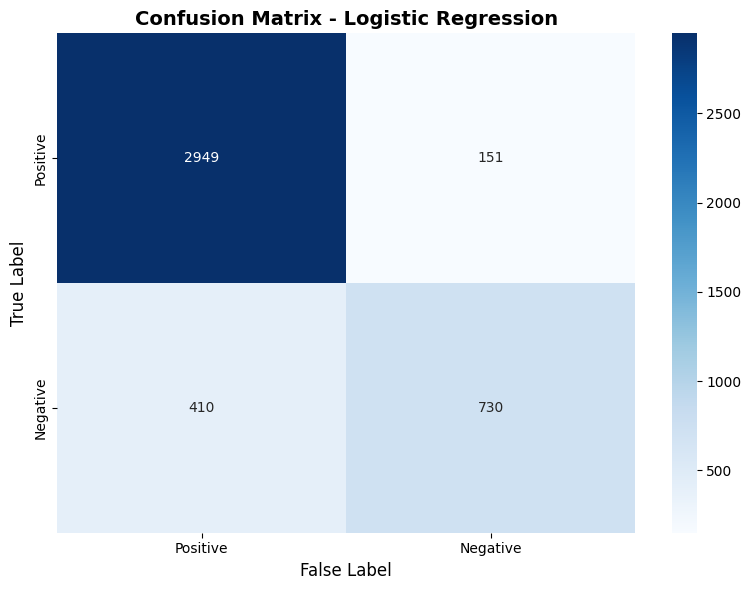


KNN Confusion Matrix:


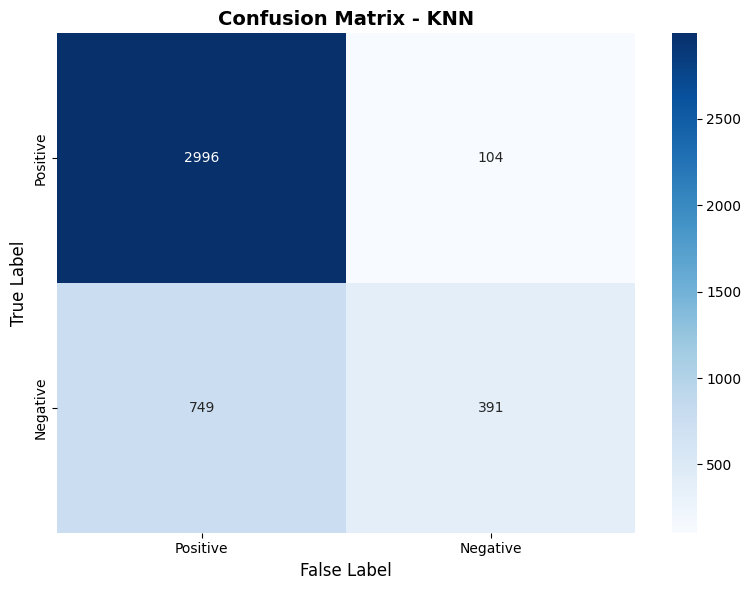

In [ ]:
# Function to plot confusion matrix
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred, labels=['Positive', 'Negative'])
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Positive', 'Negative'],
                yticklabels=['Positive', 'Negative'])
    plt.title(f'Confusion Matrix - {model_name}', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('False Label', fontsize=12)
    plt.tight_layout()
    plt.show()

    return cm

# Plot for Logistic Regression
print("Logistic Regression Confusion Matrix:")
lr_cm = plot_confusion_matrix(y_test, lr_pred, "Logistic Regression")

# Plot for KNN
print("\nKNN Confusion Matrix:")
knn_cm = plot_confusion_matrix(y_test, knn_pred, "KNN")

Side-by-Side Comparison Summary

In [ ]:
# Create comparison summary
comparison_data = {
    'Metric': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Logistic Regression': [
        accuracy_score(y_test, lr_pred),
        classification_report(y_test, lr_pred, output_dict=True)['macro avg']['precision'],
        classification_report(y_test, lr_pred, output_dict=True)['macro avg']['recall'],
        classification_report(y_test, lr_pred, output_dict=True)['macro avg']['f1-score']
    ],
    'KNN': [
        accuracy_score(y_test, knn_pred),
        classification_report(y_test, knn_pred, output_dict=True)['macro avg']['precision'],
        classification_report(y_test, knn_pred, output_dict=True)['macro avg']['recall'],
        classification_report(y_test, knn_pred, output_dict=True)['macro avg']['f1-score']
    ]
}

comparison_df = pd.DataFrame(comparison_data)
print("\n" + "="*60)
print("MODEL COMPARISON SUMMARY")
print("="*60)
print(comparison_df.to_string(index=False))

# Determine winner
winner = 'Logistic Regression' if comparison_df.loc[0, 'Logistic Regression'] > comparison_df.loc[0, 'KNN'] else 'KNN'
print(f"\nBest Model (by Accuracy): {winner}")


MODEL COMPARISON SUMMARY
           Metric  Logistic Regression      KNN
         Accuracy             0.867689 0.798821
Precision (Macro)             0.853272 0.794949
   Recall (Macro)             0.795821 0.654717
 F1-Score (Macro)             0.817780 0.676835

Best Model (by Accuracy): Logistic Regression


In [ ]:
import joblib
# Simpan TF-IDF
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

# Simpan Logistic Regression
joblib.dump(lr_model, "logistic_model.pkl")

# Simpan KNN
joblib.dump(knn_model, "knn_model.pkl")

print("Semua model berhasil disimpan.")

Semua model berhasil disimpan.
